In [1]:
# Install necessary advanced visualization and interpretability libraries
!pip install -q opencv-python seaborn plotly torch torchvision pytorch-grad-cam

from pytorch_grad_cam import GradCAM
print("Successfully imported GradCAM!")

ERROR: Could not find a version that satisfies the requirement pytorch-grad-cam (from versions: none)
ERROR: No matching distribution found for pytorch-grad-cam
Successfully imported GradCAM!


In [4]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from tqdm import tqdm

import torch
import torch.nn as nn
from torchvision import models, transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

DATA_DIR = '/home/gabor-levai/Downloads/AI_VIS/archive/train'
print("Current Working Directory:", os.getcwd())
print("Does the path exist?:", os.path.exists(DATA_DIR))
CLASSES = ['REAL', 'FAKE']

# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

Current Working Directory: /home/gabor-levai/Downloads/AI_VIS/archive
Does the path exist?: True


In [5]:
def extract_image_features(data_dir, max_samples=5000):
    """Loads image paths and calculates basic statistical features."""
    data = []
    
    for label in CLASSES:
        folder_path = os.path.join(data_dir, label)
        if not os.path.exists(folder_path):
            continue
            
        filenames = os.listdir(folder_path)[:max_samples] # Limit for memory efficiency during EDA
        
        for filename in tqdm(filenames, desc=f"Processing {label}"):
            img_path = os.path.join(folder_path, filename)
            img = cv2.imread(img_path)
            
            if img is not None:
                gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                brightness = np.mean(gray)
                contrast = np.std(gray)
                
                data.append({
                    'image_path': img_path,
                    'label': label,
                    'brightness': brightness,
                    'contrast': contrast
                })
                
    return pd.DataFrame(data)

df = extract_image_features(DATA_DIR, max_samples=5000)
df.head()

Processing FAKE: 100%|██████████| 5000/5000 [00:00<00:00, 7050.34it/s]


,image_path,label,brightness,contrast
0,/home/gabor-levai/Downloads/AI_VIS/archive/tra...,REAL,117.081055,65.445516
1,/home/gabor-levai/Downloads/AI_VIS/archive/tra...,REAL,108.179688,33.241113
2,/home/gabor-levai/Downloads/AI_VIS/archive/tra...,REAL,126.178711,93.826751
3,/home/gabor-levai/Downloads/AI_VIS/archive/tra...,REAL,92.981445,81.208323
4,/home/gabor-levai/Downloads/AI_VIS/archive/tra...,REAL,108.596680,58.792957


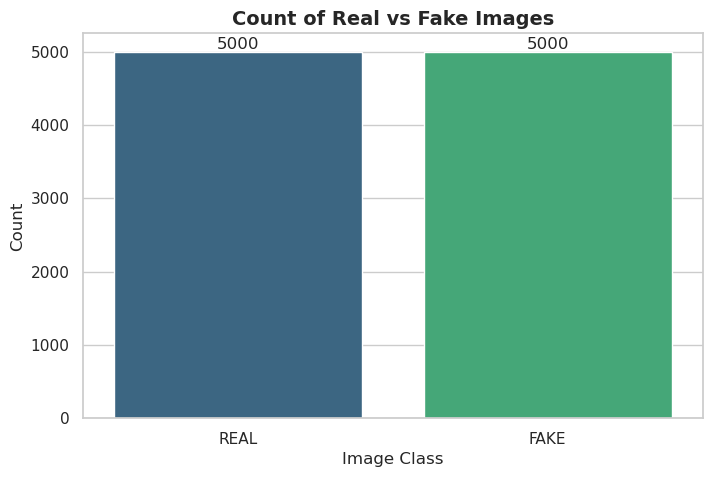

In [6]:
%matplotlib inline
plt.figure(figsize=(8, 5))

# FIX: Added hue='label' and legend=False to comply with recent Seaborn updates
ax = sns.countplot(data=df, x='label', hue='label', palette='viridis', legend=False)

plt.title('Count of Real vs Fake Images', fontsize=14, fontweight='bold')
plt.xlabel('Image Class', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Add value labels (wrapped in int() to prevent formatting errors)
for p in ax.patches:
    height = p.get_height()
    if pd.notnull(height) and height > 0:
        ax.annotate(f'{int(height)}', (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.show()

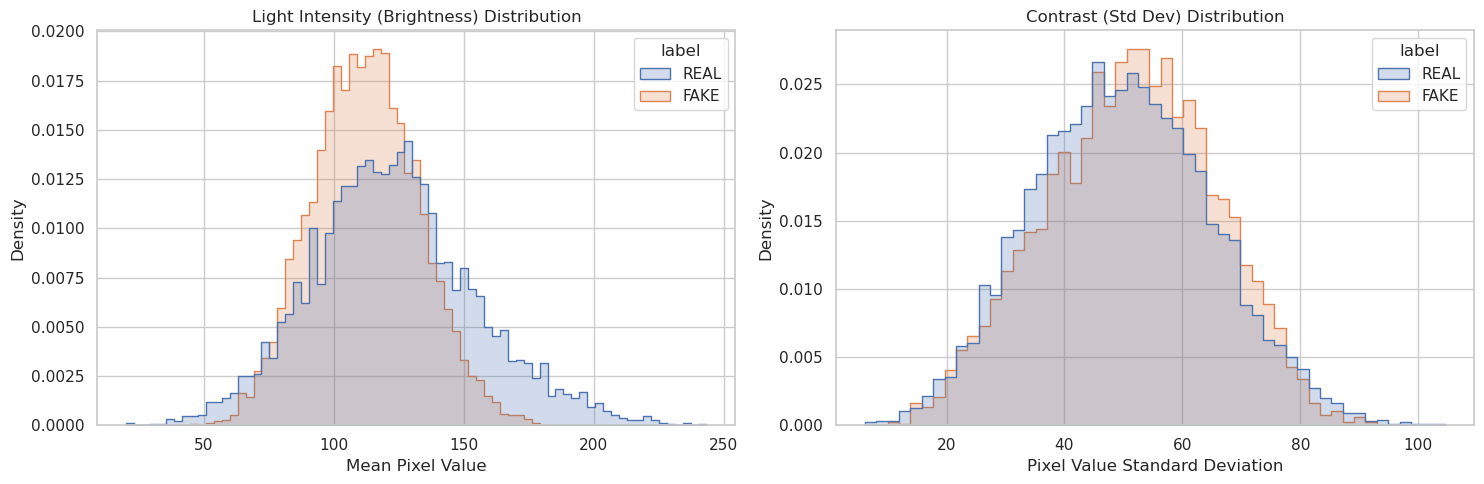

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Brightness Distribution
sns.histplot(data=df, x='brightness', hue='label', element='step', stat='density', common_norm=False, ax=axes[0])
axes[0].set_title('Light Intensity (Brightness) Distribution')
axes[0].set_xlabel('Mean Pixel Value')

# Contrast Distribution
sns.histplot(data=df, x='contrast', hue='label', element='step', stat='density', common_norm=False, ax=axes[1])
axes[1].set_title('Contrast (Std Dev) Distribution')
axes[1].set_xlabel('Pixel Value Standard Deviation')

plt.tight_layout()
plt.show()

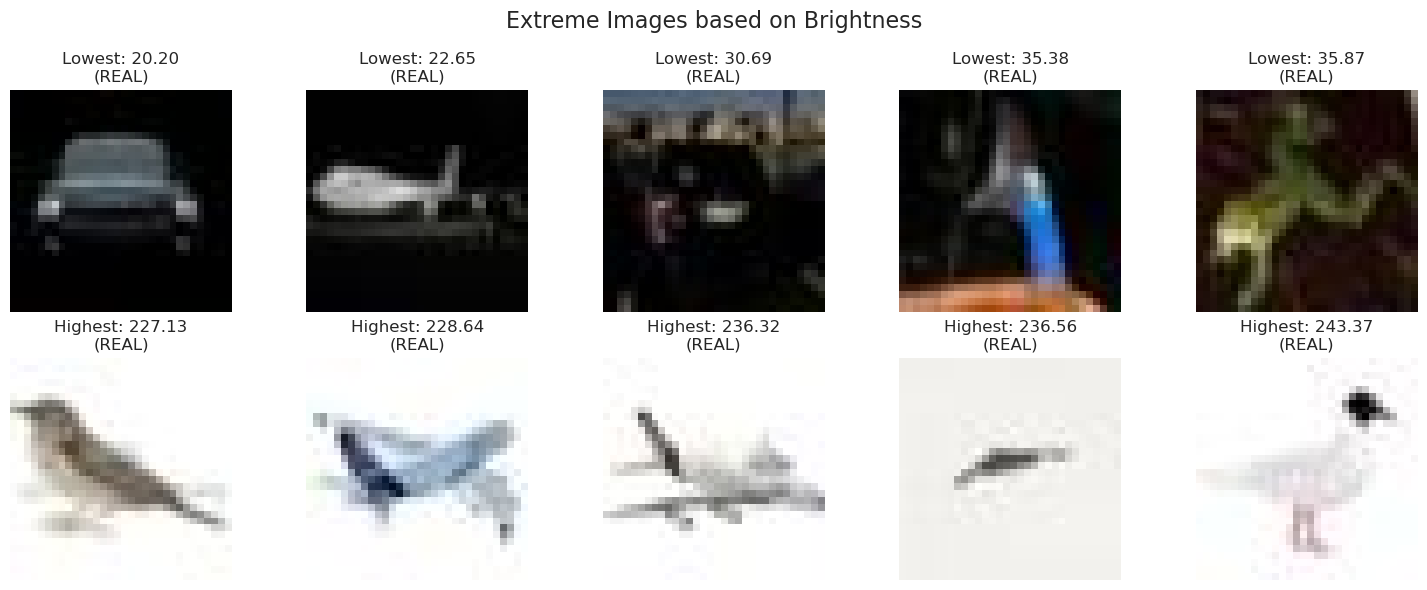

In [8]:
def plot_extremes(dataframe, feature, top_n=5):
    sorted_df = dataframe.sort_values(by=feature)
    lowest = sorted_df.head(top_n)
    highest = sorted_df.tail(top_n)
    
    fig, axes = plt.subplots(2, top_n, figsize=(15, 6))
    fig.suptitle(f'Extreme Images based on {feature.capitalize()}', fontsize=16)
    
    for i, (_, row) in enumerate(lowest.iterrows()):
        img = cv2.cvtColor(cv2.imread(row['image_path']), cv2.COLOR_BGR2RGB)
        axes[0, i].imshow(img)
        axes[0, i].set_title(f"Lowest: {row[feature]:.2f}\n({row['label']})")
        axes[0, i].axis('off')
        
    for i, (_, row) in enumerate(highest.iterrows()):
        img = cv2.cvtColor(cv2.imread(row['image_path']), cv2.COLOR_BGR2RGB)
        axes[1, i].imshow(img)
        axes[1, i].set_title(f"Highest: {row[feature]:.2f}\n({row['label']})")
        axes[1, i].axis('off')
        
    plt.tight_layout()
    plt.show()

# Visualize extremes for brightness
plot_extremes(df, 'brightness')

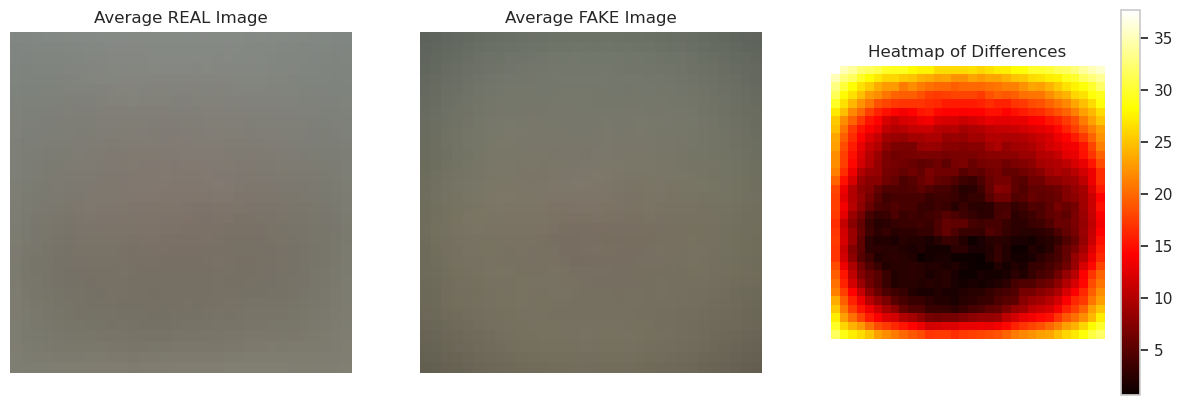

In [9]:
def generate_average_image(dataframe, label):
    paths = dataframe[dataframe['label'] == label]['image_path'].values
    avg_image = np.zeros((32, 32, 3), dtype=np.float32) # CIFAKE images are 32x32
    
    for path in paths:
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        avg_image += img
        
    avg_image /= len(paths)
    return avg_image.astype(np.uint8)

avg_real = generate_average_image(df, 'REAL')
avg_fake = generate_average_image(df, 'FAKE')
diff_image = cv2.absdiff(avg_real, avg_fake)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(avg_real)
axes[0].set_title('Average REAL Image')
axes[0].axis('off')

axes[1].imshow(avg_fake)
axes[1].set_title('Average FAKE Image')
axes[1].axis('off')

im = axes[2].imshow(np.mean(diff_image, axis=2), cmap='hot')
axes[2].set_title('Heatmap of Differences')
axes[2].axis('off')
fig.colorbar(im, ax=axes[2])

plt.show()

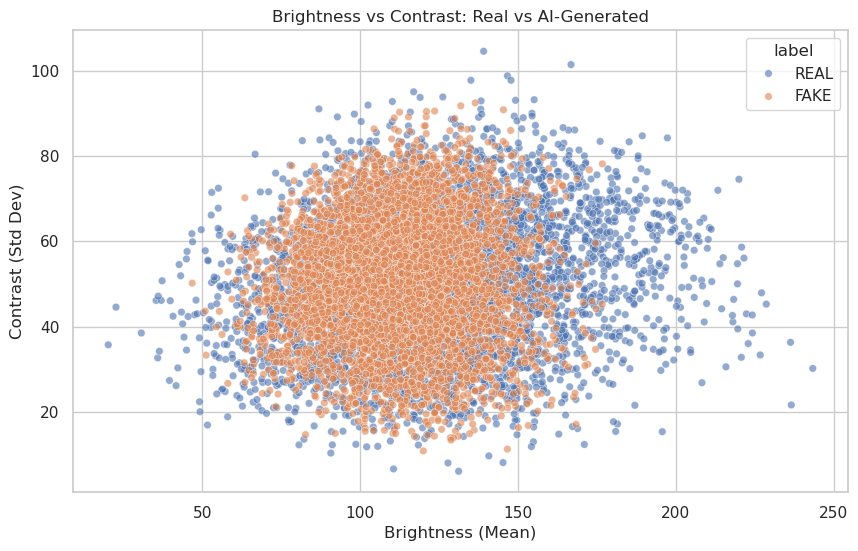

In [10]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='brightness', y='contrast', hue='label', alpha=0.6, s=30)
plt.title('Brightness vs Contrast: Real vs AI-Generated')
plt.xlabel('Brightness (Mean)')
plt.ylabel('Contrast (Std Dev)')
plt.show()

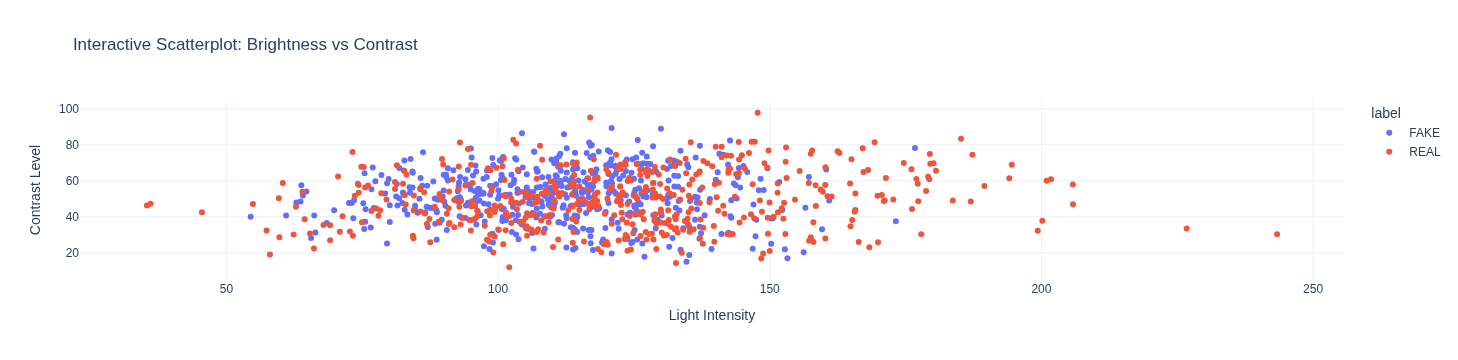

In [11]:
# Sample 1000 points to keep the interactive plot responsive
df_sample = df.sample(n=min(1000, len(df)), random_state=42)

fig = px.scatter(
    df_sample, 
    x='brightness', 
    y='contrast', 
    color='label',
    hover_data=['image_path'],
    title='Interactive Scatterplot: Brightness vs Contrast',
    labels={'brightness': 'Light Intensity', 'contrast': 'Contrast Level'}
)

fig.update_layout(template='plotly_white')
fig.show()

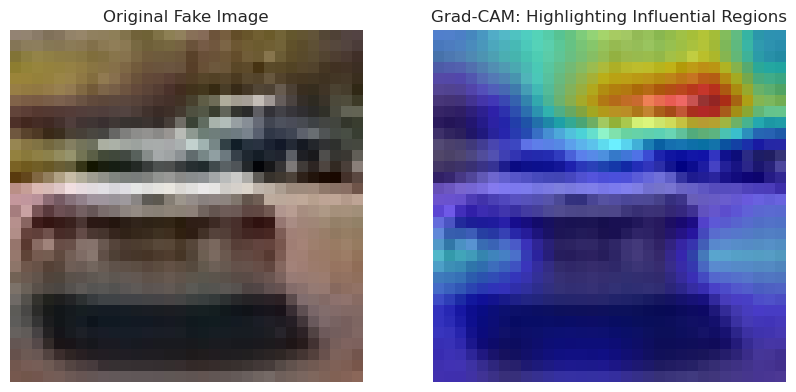

In [12]:
# Initialize a pre-trained model (in a real scenario, you would load your CIFAKE fine-tuned weights here)
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2) # 2 classes: REAL and FAKE
model.eval()

# Select the target layer for Grad-CAM
target_layers = [model.layer4[-1]]

def apply_gradcam(image_path, model, target_layers):
    # Load and preprocess image
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_float = np.float32(img) / 255
    
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Resize((224, 224), antialias=True),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    input_tensor = transform(img).unsqueeze(0)
    
    # Generate CAM
    cam = GradCAM(model=model, target_layers=target_layers)
    
    # We use a dummy target here. In practice, use ClassifierOutputTarget(0 or 1)
    targets = [ClassifierOutputTarget(1)] 
    
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    
    # Resize cam back to original image size
    grayscale_cam = cv2.resize(grayscale_cam, (img.shape[1], img.shape[0]))
    visualization = show_cam_on_image(img_float, grayscale_cam, use_rgb=True)
    
    return img, visualization

# Test Grad-CAM on a sample Fake Image
sample_path = df[df['label'] == 'FAKE']['image_path'].iloc[0]
original_img, cam_img = apply_gradcam(sample_path, model, target_layers)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(original_img)
axes[0].set_title('Original Fake Image')
axes[0].axis('off')

axes[1].imshow(cam_img)
axes[1].set_title('Grad-CAM: Highlighting Influential Regions')
axes[1].axis('off')

plt.show()

Extracting RGB: 100%|██████████| 2000/2000 [00:00<00:00, 5417.68it/s]


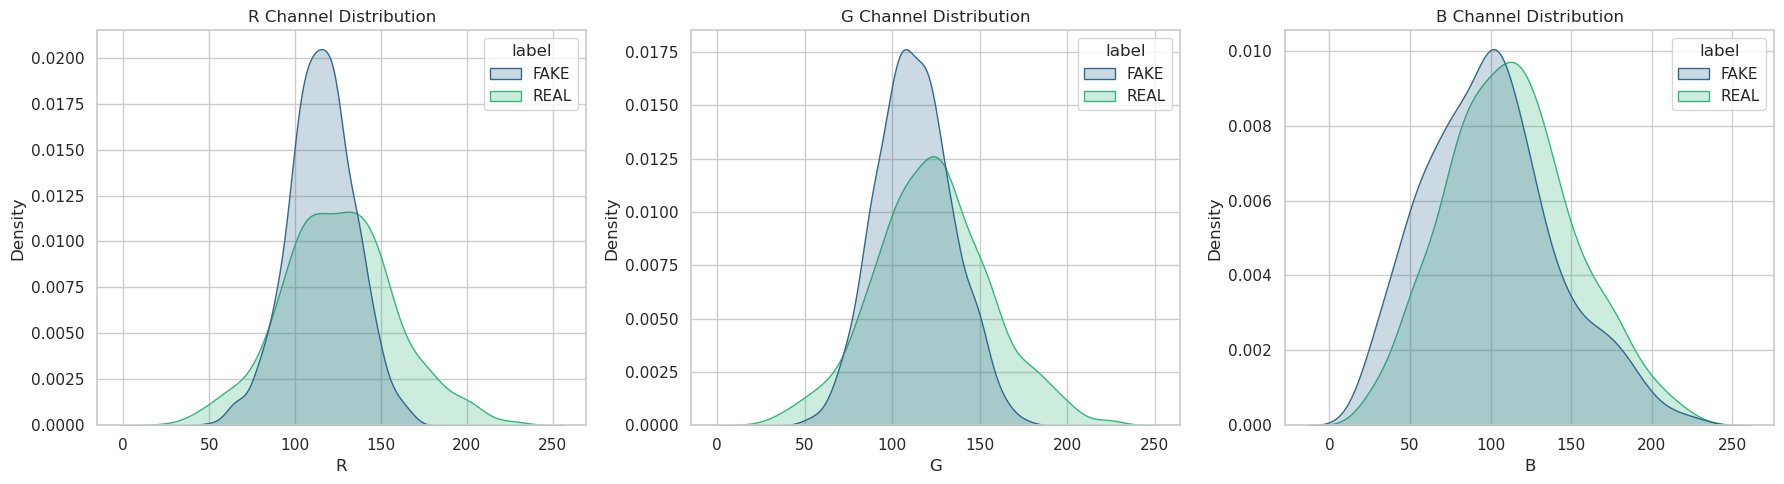

In [13]:
# Cell: RGB Channel Distribution
def get_rgb_means(dataframe, sample_size=1000):
    rgb_data = []
    sample_df = dataframe.groupby('label').sample(n=sample_size, replace=True)
    
    for _, row in tqdm(sample_df.iterrows(), total=len(sample_df), desc="Extracting RGB"):
        img = cv2.cvtColor(cv2.imread(row['image_path']), cv2.COLOR_BGR2RGB)
        r, g, b = np.mean(img[:,:,0]), np.mean(img[:,:,1]), np.mean(img[:,:,2])
        rgb_data.append({'label': row['label'], 'R': r, 'G': g, 'B': b})
        
    return pd.DataFrame(rgb_data)

rgb_df = get_rgb_means(df, sample_size=1000)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['red', 'green', 'blue']
channels = ['R', 'G', 'B']

for i, (col, chan) in enumerate(zip(colors, channels)):
    sns.kdeplot(data=rgb_df, x=chan, hue='label', fill=True, common_norm=False, ax=axes[i], palette='viridis')
    axes[i].set_title(f'{chan} Channel Distribution')
    
plt.tight_layout()
plt.show()

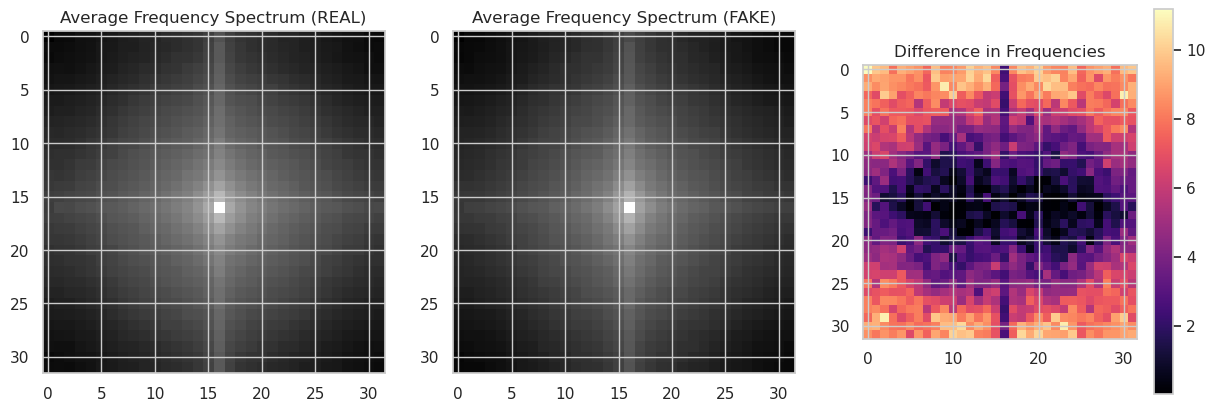

In [14]:
# Cell: Fourier Transform Spectrum
def get_average_spectrum(dataframe, label, sample_size=500):
    paths = dataframe[dataframe['label'] == label]['image_path'].sample(sample_size).values
    avg_magnitude = np.zeros((32, 32))
    
    for path in paths:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        f_transform = np.fft.fft2(img)
        f_shift = np.fft.fftshift(f_transform)
        magnitude_spectrum = 20 * np.log(np.abs(f_shift) + 1)
        avg_magnitude += magnitude_spectrum
        
    return avg_magnitude / sample_size

real_spectrum = get_average_spectrum(df, 'REAL')
fake_spectrum = get_average_spectrum(df, 'FAKE')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(real_spectrum, cmap='gray')
axes[0].set_title('Average Frequency Spectrum (REAL)')

axes[1].imshow(fake_spectrum, cmap='gray')
axes[1].set_title('Average Frequency Spectrum (FAKE)')

diff_spectrum = np.abs(real_spectrum - fake_spectrum)
im = axes[2].imshow(diff_spectrum, cmap='magma')
axes[2].set_title('Difference in Frequencies')
fig.colorbar(im, ax=axes[2])

plt.show()

Calculating Edges: 100%|██████████| 2000/2000 [00:00<00:00, 10092.59it/s]
/tmp/ipykernel_58659/2267570646.py:16: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




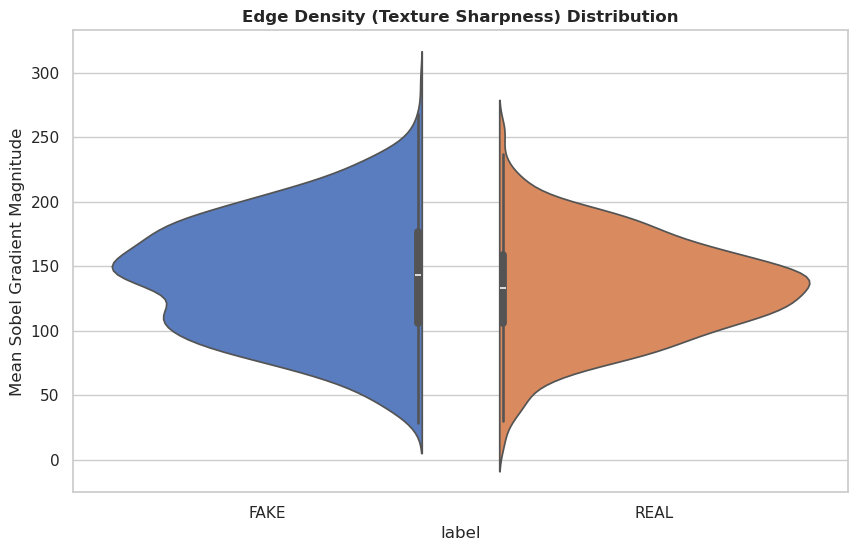

In [15]:
# Cell: Edge Density Analysis
def calculate_edge_density(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    # Calculate gradients in X and Y direction
    sobelx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = np.sqrt(sobelx**2 + sobely**2)
    return np.mean(magnitude)

# Add edge density to a sample of our dataframe
tqdm.pandas(desc="Calculating Edges")
df_sample = df.groupby('label').sample(n=1000)
df_sample['edge_density'] = df_sample['image_path'].progress_apply(calculate_edge_density)

plt.figure(figsize=(10, 6))
sns.violinplot(data=df_sample, x='label', y='edge_density', palette='muted', split=True)
plt.title('Edge Density (Texture Sharpness) Distribution', fontweight='bold')
plt.ylabel('Mean Sobel Gradient Magnitude')
plt.show()

Flattening images: 100%|██████████| 2000/2000 [00:00<00:00, 29505.46it/s]


Running PCA...
PCA completed in 0.11 seconds.
Variance explained by 50 components: 82.7%
Running t-SNE...
t-SNE completed in 2.41 seconds.


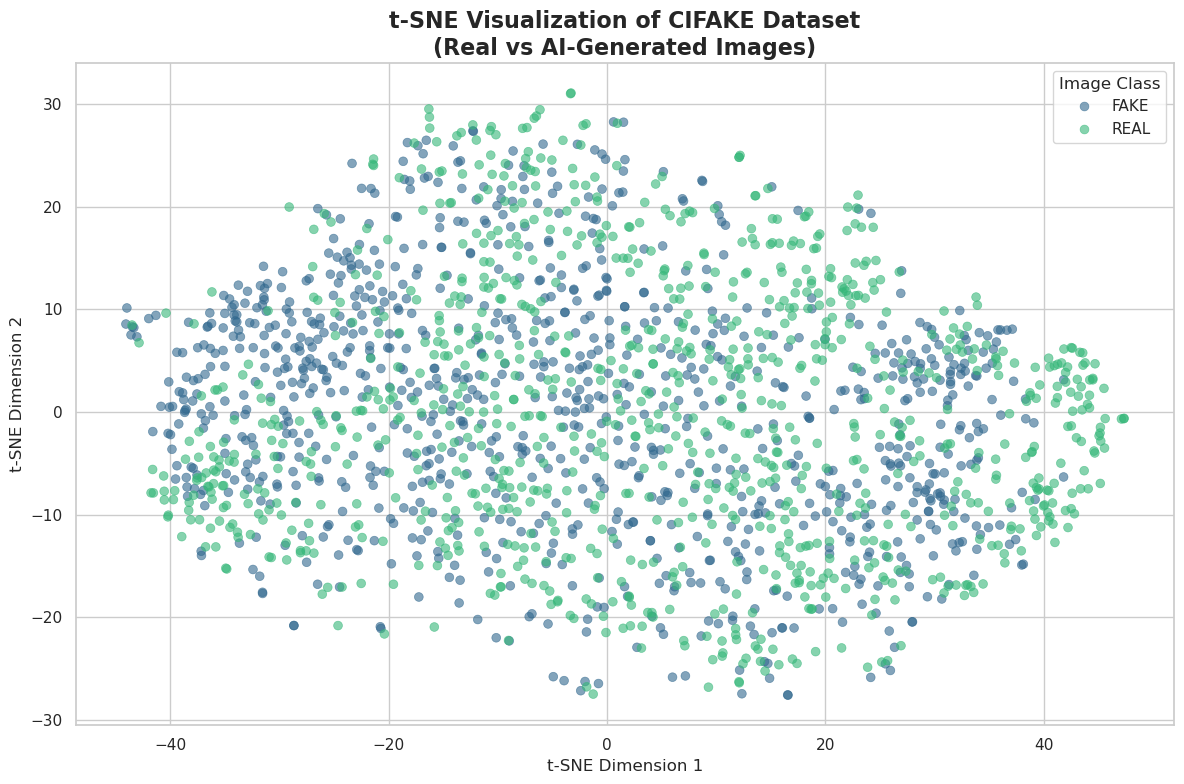

In [17]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import time

def extract_flattened_pixels(dataframe, sample_size_per_class=1000):
    """Loads and flattens images into 1D arrays for machine learning algorithms."""
    # Sample equally from both classes to prevent visual bias
    sample_df = dataframe.groupby('label').sample(n=sample_size_per_class, random_state=42)
    
    features = []
    labels = []
    
    for _, row in tqdm(sample_df.iterrows(), total=len(sample_df), desc="Flattening images"):
        # Read image, convert to RGB, and flatten to 1D (3072 features)
        img = cv2.cvtColor(cv2.imread(row['image_path']), cv2.COLOR_BGR2RGB)
        features.append(img.flatten())
        labels.append(row['label'])
        
    return np.array(features), np.array(labels)

# 1. Prepare the data
X, y = extract_flattened_pixels(df, sample_size_per_class=1000)
X = X / 255.0 # Normalize

print("Running PCA...")
start_time = time.time()
pca = PCA(n_components=50, random_state=42)
X_pca = pca.fit_transform(X)
print(f"PCA completed in {time.time() - start_time:.2f} seconds.")
print(f"Variance explained by 50 components: {np.sum(pca.explained_variance_ratio_) * 100:.1f}%")

print("Running t-SNE...")
start_time = time.time()
# FIX: Changed 'n_iter' to 'max_iter'
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42)
X_tsne = tsne.fit_transform(X_pca)
print(f"t-SNE completed in {time.time() - start_time:.2f} seconds.")

# Create DataFrame and Plot
tsne_df = pd.DataFrame({'TSNE_1': X_tsne[:, 0], 'TSNE_2': X_tsne[:, 1], 'Label': y})

plt.figure(figsize=(12, 8))
sns.scatterplot(data=tsne_df, x='TSNE_1', y='TSNE_2', hue='Label', palette='viridis', alpha=0.6, s=40, edgecolor=None)
plt.title('t-SNE Visualization of CIFAKE Dataset\n(Real vs AI-Generated Images)', fontsize=16, fontweight='bold')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend(title='Image Class', loc='best')
plt.tight_layout()
plt.show()